In [20]:
import pandas as pd
from astroquery.gaia import Gaia
import astropy.units as u
from astropy.table import Table
from astropy.coordinates import SkyCoord, Galactocentric
import matplotlib as mpl
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
import matplotlib.image as mpimg
import numpy as np

In [21]:
sample = pd.read_csv('../data/true_sources_final_XYZ.csv')
unc = pd.read_csv('../data/unconfirmed_XYZ.csv')
sample = sample.sample(frac=1, random_state=42).reset_index(drop=True) ##shuffle the data so the distances aren't ordered bc it looks weird in the plot

X = sample['X']
Y = sample['Y']
Z = sample['Z']

u_X = unc['X']
u_Y = unc['Y']
u_Z = unc['Z']

In [22]:
#read milky way images
img_faceon = mpimg.imread('../input_figures/mw_face_on.jpg')
img_edgeon = mpimg.imread('../input_figures/The_best_Milky_Way_map_by_Gaia_edge-on.jpg')

In [23]:
#set plot lims
xmin, xmax = -25, 65
ymin, ymax = -25, 65


#MW image extent
img_x_lim = 5600 * (8.125 / 1078) / 2

faceon_extent = [
    -img_x_lim,
     img_x_lim,
    -img_x_lim,
     img_x_lim
]

edgeon_extent = [-30, 30, -30, 30]

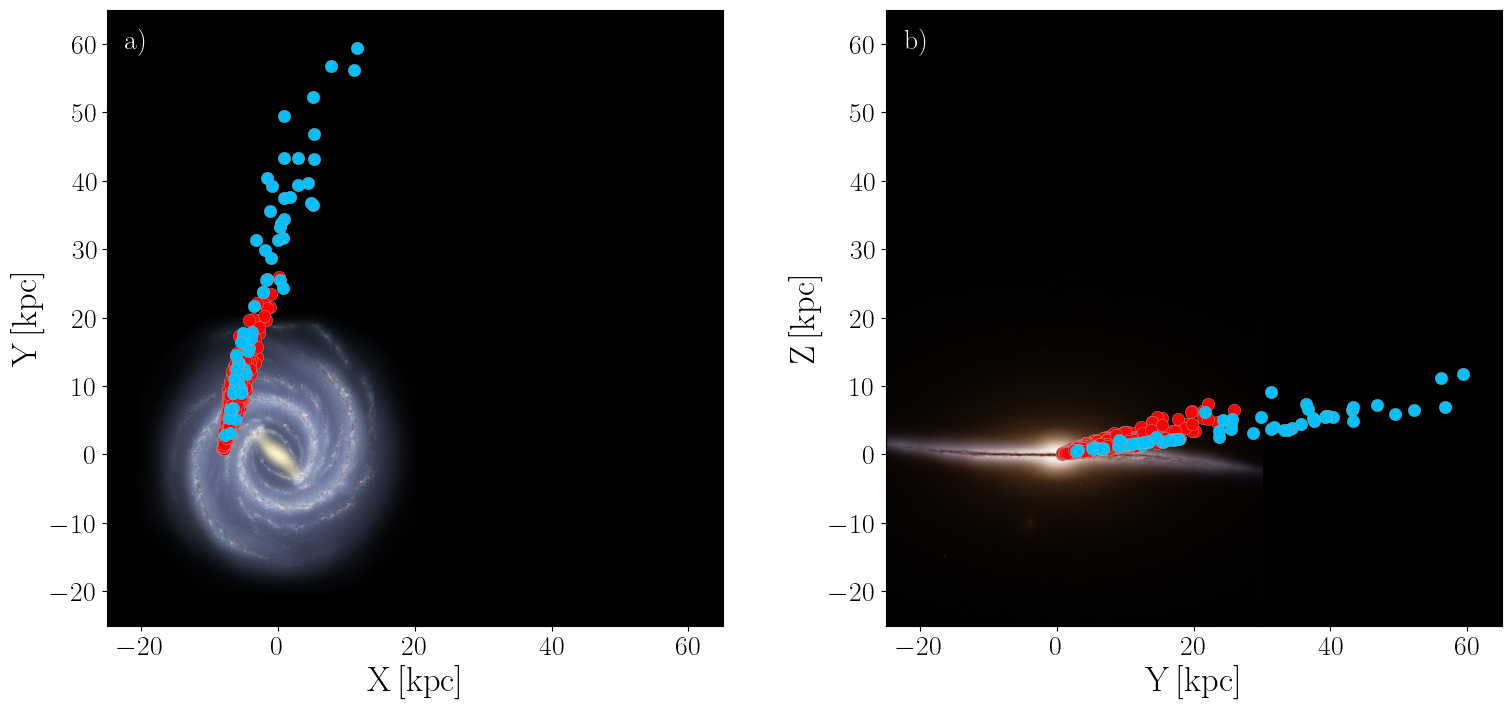

In [ ]:
#plot
fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 8),
    gridspec_kw={'wspace': 0.01}
)

#left panel
axes[0].set_facecolor('black')

axes[0].imshow(
    img_faceon,
    extent=faceon_extent,
    aspect='equal',
    origin='upper'
)

axes[0].scatter(
    sample['X'],
    sample['Y'],
    c='red',
    s=80,
    edgecolor='darkgray',
    linewidth=0.3,
    label='Confirmed',
    rasterized=True
)

axes[0].scatter(
    unc['X'],
    unc['Y'],
    c='deepskyblue',
    s=80,
    edgecolor='darkgray',
    linewidth=0.3,
    label='Unconfirmed',
    rasterized=True,
    zorder=2
)


axes[0].set_xlim(xmin, xmax)
axes[0].set_ylim(ymin, ymax)

axes[0].set_xlabel(
    r'$\mathrm{X\, [kpc]}$',
    fontsize=25
)

axes[0].set_ylabel(
    r'$\mathrm{Y\, [kpc]}$',
    fontsize=25
)

axes[0].tick_params(
    axis='both',
    which='major',
    labelsize=20
)

axes[0].set_aspect(
    'equal',
    adjustable='box'
)

#right panel
axes[1].set_facecolor('black')

axes[1].imshow(
    img_edgeon,
    extent=edgeon_extent,
    aspect='equal',
    origin='upper',
    zorder=0
)

axes[1].scatter(
    sample['Y'],
    sample['Z'],
    c='red',
    s=80,
    edgecolor='darkgray',
    linewidth=0.3,
    rasterized=True
)

axes[1].scatter(
    unc['Y'],
    unc['Z'],
    c='deepskyblue',
    s=80,
    edgecolor='darkgray',
    linewidth=0.3,
    rasterized=True
)

# Asymmetric coordinate limits
axes[1].set_xlim(xmin, xmax)
axes[1].set_ylim(ymin, ymax)

axes[1].set_xlabel(
    r'$\mathrm{Y\, [kpc]}$',
    fontsize=25
)

axes[1].set_ylabel(
    r'$\mathrm{Z\, [kpc]}$',
    fontsize=25
)

axes[1].tick_params(
    axis='both',
    which='major',
    labelsize=20
)

axes[1].set_aspect(
    'equal',
    adjustable='box'
)

# =====================================================================
# Panel labels
# =====================================================================

for ax, label in zip(
    axes,
    [r'$\mathrm{a)}$', r'$\mathrm{b)}$']
):
    ax.text(
        0.03,
        0.97,
        label,
        transform=ax.transAxes,
        fontsize=20,
        va='top',
        ha='left',
        color='white',
        fontweight='extra bold'
    )


plt.savefig(
    '../figures/mw_combined.pdf',
    format='pdf',
    bbox_inches='tight'
)

plt.show()